<a href="https://colab.research.google.com/github/bandapallijoshnasree71/Marketing-Campaign-AB-Test-Analysis_1/blob/main/Marketing_Campaign_A_B_Test_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

print("Libraries imported successfully")

Libraries imported successfully


In [16]:
df = pd.read_csv('/content/ab_data.csv')

df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0.0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0.0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0.0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0.0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1.0


In [17]:
df.shape

(271852, 5)

In [18]:
df.columns

Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted'], dtype='object')

In [19]:
df.describe()

,user_id,converted
count,271852.000000,271851.000000
mean,787875.813016,0.119775
std,91191.228830,0.324699
min,630000.000000,0.000000
25%,708920.250000,0.000000
50%,787821.500000,0.000000
75%,866752.500000,0.000000
max,945999.000000,1.000000


In [20]:
df.isnull().sum()

,0
user_id,0
timestamp,0
group,0
landing_page,0
converted,1


In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df['user_id'].duplicated().sum()

np.int64(3317)

In [23]:
df['group'].value_counts()

,count
group,
treatment,135935
control,135917


In [24]:
df['landing_page'].value_counts()

,count
landing_page,
old_page,135985
new_page,135866
ne,1


In [25]:
pd.crosstab(df['group'], df['landing_page'])

landing_page,ne,new_page,old_page
group,,,
control,0,1763,134154
treatment,1,134103,1831


In [26]:
df = df.drop_duplicates(subset='user_id', keep='first')

In [27]:
df = df[
    ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))
]

In [28]:
df.shape

(266508, 5)

In [29]:
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,0,133264
treatment,133244,0


# Exploratory Data Analysis (EDA)

In [30]:
df['group'].value_counts()

,count
group,
control,133264
treatment,133244


In [31]:
df.groupby('group')['converted'].sum()

,converted
group,
control,16067.0
treatment,15813.0


In [32]:
conversion_rate = df.groupby('group')['converted'].mean()

conversion_rate

,converted
group,
control,0.120565
treatment,0.118677


In [33]:
summary = df.groupby('group')['converted'].agg(
    users='count',
    conversions='sum',
    conversion_rate='mean'
)

summary

,users,conversions,conversion_rate
group,,,
control,133264,16067.0,0.120565
treatment,133244,15813.0,0.118677


In [34]:
summary['conversion_rate'] = summary['conversion_rate'] * 100

summary

,users,conversions,conversion_rate
group,,,
control,133264,16067.0,12.056519
treatment,133244,15813.0,11.867701


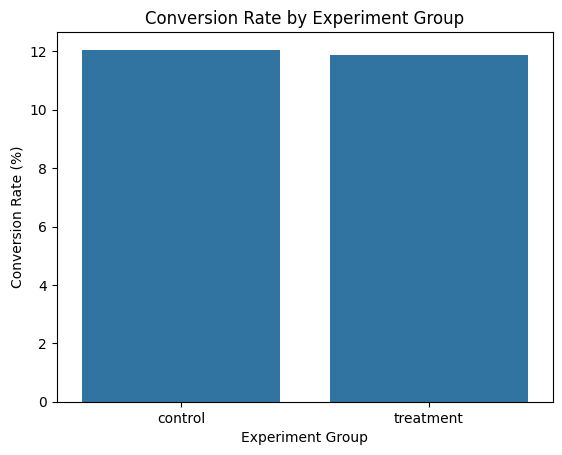

In [35]:
sns.barplot(x=summary.index, y=summary['conversion_rate'])

plt.title('Conversion Rate by Experiment Group')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate (%)')

plt.show()

# Hypothesis Formulation

# Set up the hypothesis testing values

In [36]:
alpha = 0.05

control = df[df['group'] == 'control']
treatment = df[df['group'] == 'treatment']

control_conversions = control['converted'].sum()
treatment_conversions = treatment['converted'].sum()

control_users = len(control)
treatment_users = len(treatment)

print("Control conversions:", control_conversions)
print("Treatment conversions:", treatment_conversions)

print("Control users:", control_users)
print("Treatment users:", treatment_users)

Control conversions: 16067.0
Treatment conversions: 15813.0
Control users: 133264
Treatment users: 133244


# Statistical Testing

# Perform two-proportion Z-test

In [37]:
counts = np.array([treatment_conversions, control_conversions])

nobs = np.array([treatment_users, control_users])

z_stat, p_value = proportions_ztest(
    counts,
    nobs,
    alternative='larger'
)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -1.5018610880467977
P-value: 0.9334335061017033


In [38]:
if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("There is statistical evidence that the new page increases conversions.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is insufficient statistical evidence that the new page increases conversions.")

Fail to Reject the Null Hypothesis
There is insufficient statistical evidence that the new page increases conversions.


# Confidence Interval

In [39]:
control_ci = proportion_confint(
    control_conversions,
    control_users,
    alpha=0.05,
    method='wilson'
)

treatment_ci = proportion_confint(
    treatment_conversions,
    treatment_users,
    alpha=0.05,
    method='wilson'
)

print("Control CI:", control_ci)
print("Treatment CI:", treatment_ci)

Control CI: (0.11882786838285732, 0.1223243939110523)
Treatment CI: (0.11695149585280928, 0.12042451799125495)


# Calculate absolute conversion rate difference

In [40]:
control_rate = control_conversions / control_users

treatment_rate = treatment_conversions / treatment_users

absolute_difference = treatment_rate - control_rate

print("Control Conversion Rate:", control_rate)
print("Treatment Conversion Rate:", treatment_rate)
print("Absolute Difference:", absolute_difference)
print("Absolute Difference in Percentage Points:", absolute_difference * 100)

Control Conversion Rate: 0.12056519390082843
Treatment Conversion Rate: 0.11867701359911141
Absolute Difference: -0.0018881803017170157
Absolute Difference in Percentage Points: -0.18881803017170157


In [41]:
relative_lift = ((treatment_rate - control_rate) / control_rate) * 100

print("Relative Lift (%):", relative_lift)

Relative Lift (%): -1.5661072989856


# Power Analysis

In [44]:
baseline_rate = control_rate

# Define a target improvement of 1 percentage point
target_rate = baseline_rate + 0.01

effect_size = proportion_effectsize(
    target_rate,
    baseline_rate
)

power_analysis = NormalIndPower()

required_sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=0.80,
    alpha=0.05,
    ratio=1,
    alternative='larger'
)

print("Baseline Conversion Rate:", baseline_rate)
print("Target Conversion Rate:", target_rate)
print("Effect Size:", effect_size)
print("Required Sample Size per Group:", round(required_sample_size))

Baseline Conversion Rate: 0.12056519390082843
Target Conversion Rate: 0.13056519390082844
Effect Size: 0.030184313826738696
Required Sample Size per Group: 13572


In [45]:
# Calculate the standard error for the difference

standard_error = np.sqrt(
    (treatment_rate * (1 - treatment_rate) / treatment_users) +
    (control_rate * (1 - control_rate) / control_users)
)

# Calculate the margin of error
margin_of_error = 1.96 * standard_error

# Calculate confidence interval
lower_bound = absolute_difference - margin_of_error
upper_bound = absolute_difference + margin_of_error

print("Conversion Rate Difference:", absolute_difference)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("95% Confidence Interval:", (lower_bound, upper_bound))

Conversion Rate Difference: -0.0018881803017170157
Lower Bound: -0.004352333521817419
Upper Bound: 0.0005759729183833872
95% Confidence Interval: (np.float64(-0.004352333521817419), np.float64(0.0005759729183833872))


In [46]:
print("Lower Bound (%):", lower_bound * 100)
print("Upper Bound (%):", upper_bound * 100)

Lower Bound (%): -0.4352333521817419
Upper Bound (%): 0.05759729183833873


In [47]:
if lower_bound > 0:
    print("The entire confidence interval is above zero.")
    print("The treatment shows a positive conversion rate improvement.")

elif upper_bound < 0:
    print("The entire confidence interval is below zero.")
    print("The treatment shows a conversion rate decline.")

else:
    print("The confidence interval includes zero.")
    print("The true difference may be positive, negative, or zero.")

The confidence interval includes zero.
The true difference may be positive, negative, or zero.


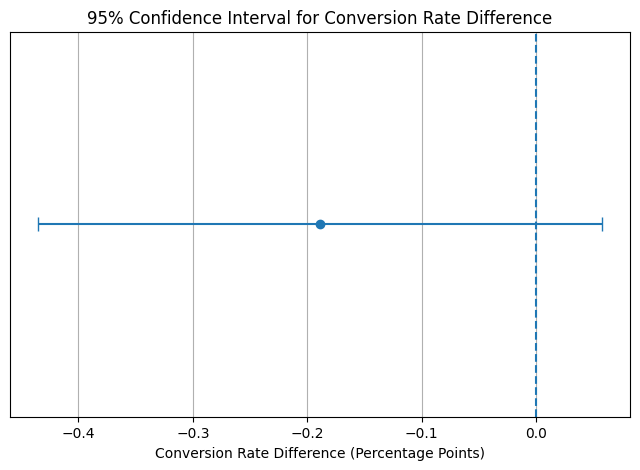

In [48]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    x=absolute_difference * 100,
    y=1,
    xerr=[
        [(absolute_difference - lower_bound) * 100],
        [(upper_bound - absolute_difference) * 100]
    ],
    fmt='o',
    capsize=5
)

plt.axvline(x=0, linestyle='--')

plt.title('95% Confidence Interval for Conversion Rate Difference')
plt.xlabel('Conversion Rate Difference (Percentage Points)')
plt.yticks([])
plt.grid(True)

plt.show()

In [49]:
results = pd.DataFrame({
    'Metric': [
        'Total Users',
        'Total Conversions',
        'Conversion Rate (%)'
    ],
    'Control': [
        control_users,
        control_conversions,
        control_rate * 100
    ],
    'Treatment': [
        treatment_users,
        treatment_conversions,
        treatment_rate * 100
    ]
})

results

,Metric,Control,Treatment
0,Total Users,133264.000000,133244.000000
1,Total Conversions,16067.000000,15813.000000
2,Conversion Rate (%),12.056519,11.867701


In [50]:
print("Absolute Difference (percentage points):", round(absolute_difference * 100, 4))
print("Relative Lift (%):", round(relative_lift, 4))
print("Z-statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 6))
print("95% Confidence Interval (%):",
      (round(lower_bound * 100, 4), round(upper_bound * 100, 4)))

Absolute Difference (percentage points): -0.1888
Relative Lift (%): -1.5661
Z-statistic: -1.5019
P-value: 0.933434
95% Confidence Interval (%): (np.float64(-0.4352), np.float64(0.0576))


In [51]:
if p_value < alpha and treatment_rate > control_rate and lower_bound > 0:
    recommendation = "SHIP"
    reason = "The treatment shows statistically significant evidence of improvement."
else:
    recommendation = "DON'T SHIP"
    reason = "There is insufficient evidence to recommend the new landing page based on conversion improvement."

print("FINAL RECOMMENDATION:", recommendation)
print("REASON:", reason)

FINAL RECOMMENDATION: DON'T SHIP
REASON: There is insufficient evidence to recommend the new landing page based on conversion improvement.


In [52]:
print("=" * 60)
print("              EXECUTIVE SUMMARY")
print("=" * 60)

print("\nOBJECTIVE:")
print("Evaluate whether the new landing page improves conversion rates.")

print("\nEXPERIMENT RESULTS:")
print(f"Control Users: {control_users}")
print(f"Treatment Users: {treatment_users}")

print(f"Control Conversion Rate: {control_rate * 100:.2f}%")
print(f"Treatment Conversion Rate: {treatment_rate * 100:.2f}%")

print(f"Absolute Difference: {absolute_difference * 100:.4f} percentage points")
print(f"Relative Lift: {relative_lift:.2f}%")

print("\nSTATISTICAL ANALYSIS:")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"95% Confidence Interval: ({lower_bound * 100:.4f}%, {upper_bound * 100:.4f}%)")

if p_value < alpha and treatment_rate > control_rate and lower_bound > 0:
    print("\nDECISION: SHIP")
    print("The results support a conversion improvement.")
else:
    print("\nDECISION: DON'T SHIP")
    print("The results do not provide sufficient evidence to recommend the new page.")

print("\nBUSINESS INTERPRETATION:")
if treatment_rate > control_rate:
    print("The treatment page had a higher observed conversion rate.")
else:
    print("The treatment page had a lower observed conversion rate.")

if p_value < alpha:
    print("The result is statistically significant based on the selected test.")
else:
    print("The result is not statistically significant at the 5% level.")

print("\nRECOMMENDATION:")
print("Retain the existing landing page unless further evidence justifies a change.")
print("=" * 60)

              EXECUTIVE SUMMARY

OBJECTIVE:
Evaluate whether the new landing page improves conversion rates.

EXPERIMENT RESULTS:
Control Users: 133264
Treatment Users: 133244
Control Conversion Rate: 12.06%
Treatment Conversion Rate: 11.87%
Absolute Difference: -0.1888 percentage points
Relative Lift: -1.57%

STATISTICAL ANALYSIS:
Z-statistic: -1.5019
P-value: 0.933434
95% Confidence Interval: (-0.4352%, 0.0576%)

DECISION: DON'T SHIP
The results do not provide sufficient evidence to recommend the new page.

BUSINESS INTERPRETATION:
The treatment page had a lower observed conversion rate.
The result is not statistically significant at the 5% level.

RECOMMENDATION:
Retain the existing landing page unless further evidence justifies a change.


In [53]:
report = f"""
# Marketing Campaign A/B Test Analysis

## Objective
Evaluate whether a new landing page improves website conversion rates.

## Experiment Results

| Metric | Control | Treatment |
|---|---:|---:|
| Users | {control_users} | {treatment_users} |
| Conversions | {control_conversions} | {treatment_conversions} |
| Conversion Rate | {control_rate*100:.2f}% | {treatment_rate*100:.2f}% |

## Statistical Results

- Absolute Difference: {absolute_difference*100:.4f} percentage points
- Relative Lift: {relative_lift:.2f}%
- Z-statistic: {z_stat:.4f}
- P-value: {p_value:.6f}
- 95% Confidence Interval: ({lower_bound*100:.4f}%, {upper_bound*100:.4f}%)

## Hypothesis Testing

- Null Hypothesis: The new landing page does not improve conversion rates.
- Alternative Hypothesis: The new landing page improves conversion rates.
- Significance Level: 5%

## Decision

{recommendation}

## Business Interpretation

The experiment was conducted to determine whether the new landing page
improves conversion rates. The observed difference, p-value and confidence
interval were evaluated to assess the evidence for an improvement.

The decision should consider statistical significance, practical significance,
experiment validity and business costs.

## Power Analysis

A sample size of 13,572 users per group was estimated to detect a
1 percentage-point absolute improvement from the baseline conversion
rate, assuming 80% power, a 5% significance level and equal group allocation.
"""

with open("executive_summary.md", "w") as file:
    file.write(report)

print("Executive summary saved successfully!")

Executive summary saved successfully!


In [54]:
from google.colab import files

files.download("executive_summary.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>